In [1]:
import pandas as pd, numpy as np, re, time
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60)

NEED = ['record_id','full_name','email','phone','address','zip_code','city','source_system','true_customer_id',
        'phone_c','addr_c','first','last_core','last_sdx','em_local','em_digits']
c = pd.read_csv('cleaned_customers.csv', usecols=NEED, low_memory=False,
                dtype={'phone_c': str, 'em_digits': str, 'zip_code': str})
p = pd.read_csv('candidate_pairs.csv')
print(c.shape, p.shape)
c.head(3)

(185000, 16) (784350, 2)


,record_id,source_system,full_name,email,phone,address,city,zip_code,true_customer_id,phone_c,addr_c,first,last_core,last_sdx,em_local,em_digits
0,CRM0000001,CRM,Nathan Nance,nnance17@example.com,NaN,1142 Noah Road,Graham,27253,CUST073258,NaN,1142 noah rd,nathan,nance,N520,nnance17,17
1,CRM0000002,CRM,Jonathan L. Henson,jonathan.henson3@mail.example,NaN,4881 Grosbeak Ct,Mebane,27302,CUST008947,NaN,4881 grosbeak ct,jonathan,henson,H525,jonathan.henson3,3
2,CRM0000003,CRM,Dylan H. Wilkerson,dylan_wilkerson70@example.org,(336) 212-8627,5609 Herring Hillside Dr,Graham,27253,CUST052862,3362128627,5609 herring hillside dr,dylan,wilkerson,W426,dylan_wilkerson70,70


## 1. String similarity functions
If the fast library `rapidfuzz` is installed it is used; otherwise pure-Python versions of the same two formulas are used (slower but identical idea). Install with `pip install rapidfuzz` for about 10x speed.

In [2]:
try:
    from rapidfuzz.distance import JaroWinkler as _JW, Levenshtein as _LEV
    def jw(a, b):  return _JW.similarity(a, b)
    def lev(a, b): return _LEV.normalized_similarity(a, b)
    ENGINE = 'rapidfuzz'
except ImportError:
    ENGINE = 'pure python'
    def jaro(s1, s2):
        if s1 == s2: return 1.0
        l1, l2 = len(s1), len(s2)
        if l1 == 0 or l2 == 0: return 0.0
        md = max(l1, l2)//2 - 1
        m1, m2 = [False]*l1, [False]*l2; m = 0
        for i, ch in enumerate(s1):
            for j in range(max(0, i-md), min(l2, i+md+1)):
                if not m2[j] and s2[j] == ch: m1[i] = m2[j] = True; m += 1; break
        if m == 0: return 0.0
        k = t = 0
        for i in range(l1):
            if m1[i]:
                while not m2[k]: k += 1
                if s1[i] != s2[k]: t += 1
                k += 1
        return (m/l1 + m/l2 + (m - t/2)/m)/3
    def jw(a, b):
        j = jaro(a, b)
        if j > 0.7:
            l = 0
            for x, y in zip(a[:4], b[:4]):
                if x == y: l += 1
                else: break
            j += l*0.1*(1-j)
        return j
    def lev(a, b):
        if a == b: return 1.0
        if not a or not b: return 0.0
        if len(a) < len(b): a, b = b, a
        prev = list(range(len(b)+1))
        for i, ca in enumerate(a, 1):
            cur = [i]
            for j, cb in enumerate(b, 1):
                cur.append(min(prev[j]+1, cur[j-1]+1, prev[j-1]+(ca != cb)))
            prev = cur
        return 1 - prev[-1]/len(a)
print('engine:', ENGINE)
for x, y in [('wrenn','wrrenn'), ('katherine','kate'), ('john','jhon'), ('smith','jones')]:
    print(f'{x:10s} {y:10s}  JW={jw(x,y):.3f}  Lev={lev(x,y):.3f}')

engine: rapidfuzz
wrenn      wrrenn      JW=0.956  Lev=0.833
katherine  kate        JW=0.870  Lev=0.444
john       jhon        JW=0.925  Lev=0.500
smith      jones       JW=0.000  Lev=0.000


## 2. Nickname table
About half of the true duplicate pairs write the first name differently: about 17% only as an initial (`K.`), about 29% with a typo (`jhon`/`john`), and about 3% as a nickname (`mike`/`michael`, `bill`/`william`). The table below is a standard English nickname list; every name in a row maps to the first (formal) name.

In [3]:
NICK_GROUPS = '''
michael mike mikey mick
james jim jimmy jamie
william bill billy will willy liam
robert bob bobby rob robbie bert
david dave davy
christopher chris
jennifer jen jenny jenn
charles chuck charlie chas
thomas tom tommy
richard rick ricky dick rich
joseph joe joey
matthew matt
elizabeth liz beth betty lizzie eliza libby
daniel dan danny
kimberly kim kimmy
patricia pat patty trish tricia
jessica jess jessie
deborah debbie deb debra
steven steve stephen stevie
jonathan jon jonny
susan sue susie suzy
rebecca becky becca
timothy tim timmy
anthony tony
katherine kate katie kathy kat kathryn catherine cathy
margaret peggy maggie meg marge
nicholas nick nicky
alexander alex al
benjamin ben benny
samantha sam sammy
andrew andy drew
edward ed eddie ted teddy
gregory greg
jeffrey jeff
joshua josh
kenneth ken kenny
lawrence larry
ronald ron ronnie
donald don donnie
theodore ted theo
victoria vicky tori
abigail abby
amanda mandy
barbara barb barbie
cynthia cindy
dorothy dot dottie
frances fran frannie
gerald gerry jerry
henry hank harry
isabella izzy bella
jacqueline jackie
judith judy
leonard leo lenny
nathaniel nate nathan
pamela pam
phillip phil
raymond ray
rosemary rosie
sandra sandy
stephanie steph stephie
sylvia syl
vincent vince vinny
walter walt wally
zachary zach zack
'''
NICK = {}
for line in NICK_GROUPS.strip().splitlines():
    names = line.split()
    for nm in names: NICK[nm] = names[0]
canon = lambda s: NICK.get(s, s)
print(len(NICK), 'names mapped |', canon('kate'), canon('bill'), canon('mike'), canon('smith'))

203 names mapped | katherine william michael smith


## 3. Prepare record-level arrays (memory-friendly)
Instead of building two huge copies of the data for 784k pairs, we keep one small array per field for the 185k **records** and look up the two records of each pair on the fly. Pairs are processed in chunks of 100,000 and stored as `float32`, so RAM stays low.

In [4]:
def col(name): return c[name].fillna('').astype(str).values
R = {
  'first': col('first'), 'last': col('last_core'), 'sdx': col('last_sdx'),
  'em': col('em_local'), 'dig': col('em_digits'), 'ph': col('phone_c'), 'ad': col('addr_c'),
  'zip': col('zip_code'), 'city': col('city'),
  'house': c.addr_c.fillna('').str.extract(r'^(\d+)')[0].fillna('').values,
  'dom': c.email.fillna('').str.split('@').str[-1].str.lower().values,
}
src = (c.source_system.values == 'BILLING')
tid = c.true_customer_id.astype('category').cat.codes.values      # integer code per true customer (evaluation only)
ia_all, ib_all = p.idx_a.values, p.idx_b.values
N = len(p); print('records:', len(c), '| pairs:', N)

records: 185000 | pairs: 784350


## 4. Compute the similarity features (in chunks)
Rule for every field: if either side is empty the score is `NaN` (unknown), not 0.

In [5]:
nan = np.nan
def both(x, y): return bool(x) and bool(y)
def sim(f, x, y): return f(x, y) if both(x, y) else nan
def eq(x, y):     return float(x == y) if both(x, y) else nan
def init_match(x, y):
    # one side is a single letter (initial) that equals the first letter of the other
    if not both(x, y): return nan
    if len(x) == 1 or len(y) == 1: return float(x[0] == y[0])
    return 0.0

def features(ia, ib):
    g = lambda k: (R[k][ia], R[k][ib])
    fa, fb = g('first'); la, lb = g('last'); sa, sb = g('sdx'); ea, eb = g('em'); da, db = g('dig')
    pa, pb = g('ph'); aa, ab = g('ad'); ha, hb = g('house'); za, zb = g('zip'); ca, cb = g('city'); Da, Db = g('dom')
    F = {
      'first_exact':  [eq(x, y) for x, y in zip(fa, fb)],
      'first_jw':     [sim(jw, x, y) for x, y in zip(fa, fb)],
      'first_nick':   [eq(canon(x), canon(y)) if both(x, y) else nan for x, y in zip(fa, fb)],
      'first_initial':[init_match(x, y) for x, y in zip(fa, fb)],
      'last_exact':   [eq(x, y) for x, y in zip(la, lb)],
      'last_jw':      [sim(jw, x, y) for x, y in zip(la, lb)],
      'last_lev':     [sim(lev, x, y) for x, y in zip(la, lb)],
      'last_sdx_eq':  [eq(x, y) for x, y in zip(sa, sb)],
      'email_exact':  [eq(x, y) for x, y in zip(ea, eb)],
      'email_jw':     [sim(jw, x, y) for x, y in zip(ea, eb)],
      'email_lev':    [sim(lev, x, y) for x, y in zip(ea, eb)],
      'email_digits_eq': [eq(x, y) for x, y in zip(da, db)],
      'email_domain_eq': [eq(x, y) for x, y in zip(Da, Db)],
      'phone_eq':     [eq(x, y) for x, y in zip(pa, pb)],
      'addr_exact':   [eq(x, y) for x, y in zip(aa, ab)],
      'addr_lev':     [sim(lev, x, y) for x, y in zip(aa, ab)],
      'addr_jw':      [sim(jw, x, y) for x, y in zip(aa, ab)],
      'house_eq':     [eq(x, y) for x, y in zip(ha, hb)],
      'zip_eq':       [eq(x, y) for x, y in zip(za, zb)],
      'city_eq':      [eq(x, y) for x, y in zip(ca, cb)],
      'miss_email':   [float(not both(x, y)) for x, y in zip(ea, eb)],
      'miss_phone':   [float(not both(x, y)) for x, y in zip(pa, pb)],
      'miss_addr':    [float(not both(x, y)) for x, y in zip(aa, ab)],
      'cross_system': (src[ia] != src[ib]).astype(float),
    }
    return pd.DataFrame(F).astype('float32')

CHUNK = 100_000
t = time.time(); parts = []
for s0 in range(0, N, CHUNK):
    parts.append(features(ia_all[s0:s0+CHUNK], ib_all[s0:s0+CHUNK]))
    print(f'  {min(s0+CHUNK, N):>8,} / {N:,} pairs  ({time.time()-t:.0f}s)')
F = pd.concat(parts, ignore_index=True); del parts
print(f'features computed in {time.time()-t:.0f}s | shape {F.shape} | memory {F.memory_usage(deep=True).sum()/1e6:.0f} MB')
F.head()

   100,000 / 784,350 pairs  (6s)
   200,000 / 784,350 pairs  (11s)
   300,000 / 784,350 pairs  (16s)
   400,000 / 784,350 pairs  (21s)
   500,000 / 784,350 pairs  (27s)
   600,000 / 784,350 pairs  (32s)
   700,000 / 784,350 pairs  (37s)
   784,350 / 784,350 pairs  (41s)
features computed in 42s | shape (784350, 24) | memory 75 MB


,first_exact,first_jw,first_nick,first_initial,last_exact,last_jw,last_lev,last_sdx_eq,email_exact,email_jw,email_lev,email_digits_eq,email_domain_eq,phone_eq,addr_exact,addr_lev,addr_jw,house_eq,zip_eq,city_eq,miss_email,miss_phone,miss_addr,cross_system
0,1.0,1.000000,1.0,0.0,1.0,1.000000,1.000000,1.0,1.0,1.000000,1.000000,1.0,1.0,NaN,1.0,1.0000,1.000000,1.0,1.0,1.0,0.0,1.0,0.0,0.0
1,1.0,1.000000,1.0,0.0,1.0,1.000000,1.000000,1.0,1.0,1.000000,1.000000,1.0,1.0,NaN,1.0,1.0000,1.000000,1.0,1.0,1.0,0.0,1.0,0.0,1.0
2,0.0,0.854167,1.0,0.0,0.0,0.666667,0.500000,0.0,0.0,0.900057,0.764706,1.0,0.0,NaN,0.0,0.1875,0.545635,0.0,1.0,1.0,0.0,1.0,0.0,1.0
3,0.0,0.511905,0.0,0.0,0.0,0.577778,0.333333,0.0,0.0,0.548611,0.125000,0.0,1.0,NaN,1.0,1.0000,1.000000,1.0,1.0,1.0,0.0,1.0,0.0,1.0
4,1.0,1.000000,1.0,0.0,1.0,1.000000,1.000000,1.0,1.0,1.000000,1.000000,1.0,0.0,NaN,1.0,1.0000,1.000000,1.0,1.0,1.0,0.0,1.0,0.0,1.0


## 5. Add ids and the label (evaluation only)

In [6]:
out = pd.concat([p.reset_index(drop=True), F], axis=1)
out.insert(2, 'tid_a', c.true_customer_id.values[ia_all])
out.insert(3, 'tid_b', c.true_customer_id.values[ib_all])
out['label'] = (tid[ia_all] == tid[ib_all]).astype('int8')
del F
print(out.label.value_counts().rename({1:'same customer', 0:'different customer'}))
print(f'positive rate: {out.label.mean():.3%}  (imbalanced: Step 4 must handle this)')

label
different customer    666362
same customer         117988
Name: count, dtype: int64
positive rate: 15.043%  (imbalanced: Step 4 must handle this)


## 6. Do the features separate duplicates from non-duplicates?
We compare each feature for **same** vs **different** pairs, and measure how well it ranks pairs on its own with ROC-AUC (0.5 = useless, 1.0 = perfect). Missing values are set to -1 only for this AUC check.

In [7]:
feat = [x for x in out.columns if x not in ('idx_a','idx_b','tid_a','tid_b','label')]
rows = []
for f in feat:
    v = out[f]; m = out.label
    rows.append((f, v.notna().mean(), v[m==1].mean(), v[m==0].mean(), roc_auc_score(m, v.fillna(-1))))
tab = pd.DataFrame(rows, columns=['feature','coverage','mean_same','mean_diff','AUC']).sort_values('AUC', ascending=False)
tab.round(3)

,feature,coverage,mean_same,mean_diff,AUC
9,email_jw,0.959,0.995,0.636,0.951
10,email_lev,0.959,0.980,0.391,0.951
1,first_jw,1.000,0.931,0.577,0.928
11,email_digits_eq,0.959,0.978,0.069,0.910
8,email_exact,0.959,0.788,0.000,0.855
12,email_domain_eq,0.959,0.797,0.168,0.782
17,house_eq,0.932,0.977,0.296,0.771
16,addr_jw,0.932,0.997,0.686,0.767
15,addr_lev,0.932,0.988,0.462,0.767
5,last_jw,1.000,0.993,0.773,0.765


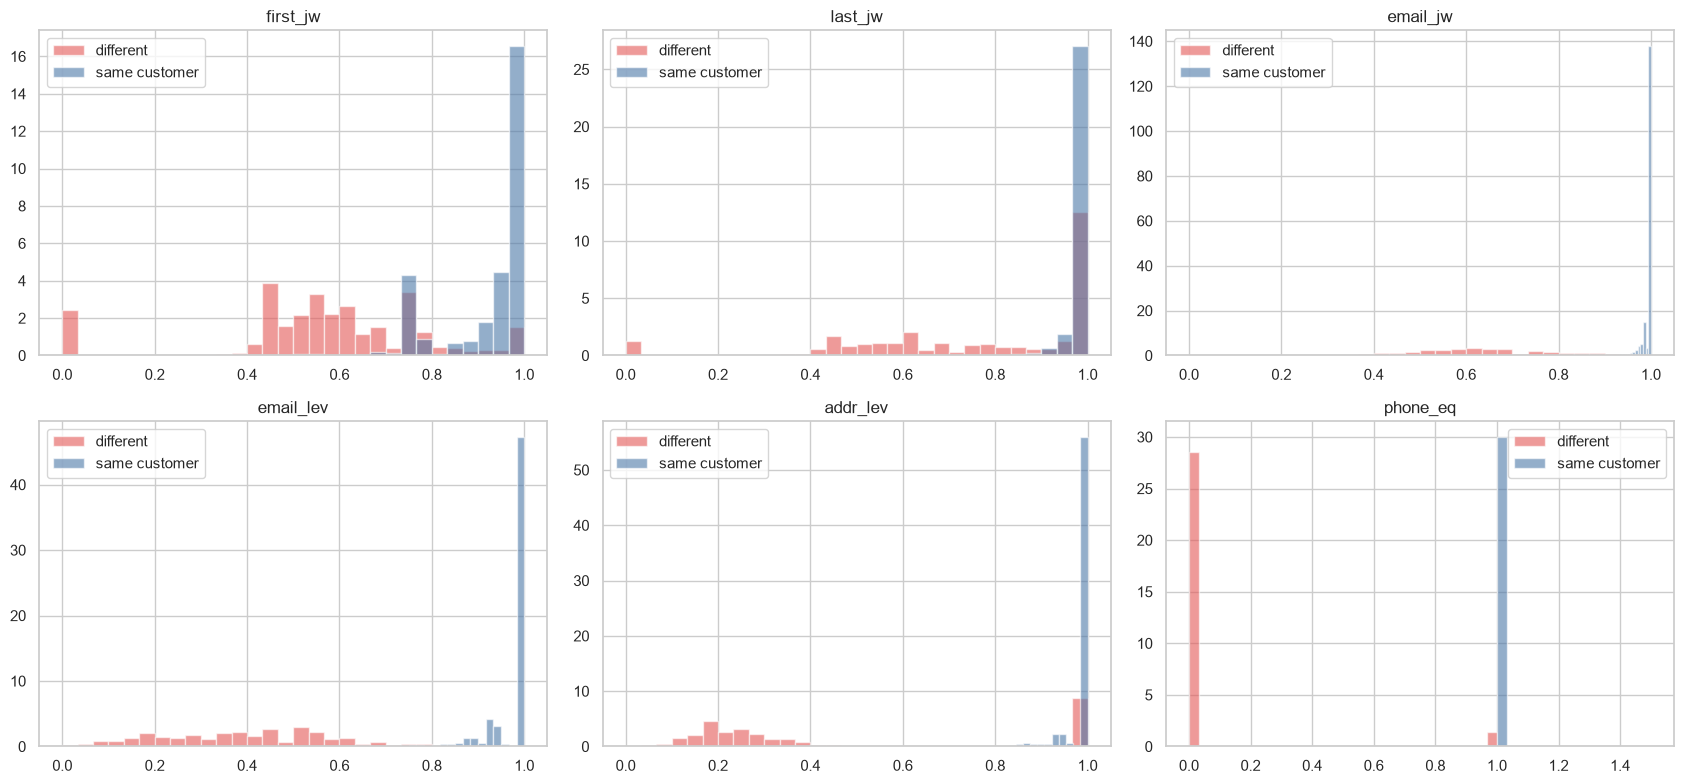

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, f in zip(ax.ravel(), ['first_jw','last_jw','email_jw','email_lev','addr_lev','phone_eq']):
    for lab, colr, nm in [(0,'#E45756','different'), (1,'#4C78A8','same customer')]:
        a.hist(out.loc[out.label==lab, f].dropna(), bins=30, alpha=.6, color=colr, label=nm, density=True)
    a.set_title(f); a.legend()
plt.tight_layout(); plt.show()

## 7. How did the first names agree on real duplicates?
This shows why nickname and initial features matter.

In [9]:
pos = out[out.label==1]
first_type = np.select(
    [pos.first_exact==1, pos.first_nick==1, pos.first_initial==1, pos.first_jw>=0.85],
    ['exact', 'nickname (Kate/Katherine)', 'initial (K.)', 'typo (JW >= 0.85)'], 'other / unmatched')
print(pd.Series(first_type).value_counts().to_frame('true pairs').assign(share=lambda d: (d['true pairs']/len(pos)).round(3)))

print()
print('Evidence available on true duplicate pairs:')
ev = pd.DataFrame({'email present on both': 1-pos.miss_email.mean(), 'phone present on both': 1-pos.miss_phone.mean(),
                   'address present on both': 1-pos.miss_addr.mean()}, index=['share']).T
ev.round(3)

                           true pairs  share
exact                           58744  0.498
typo (JW >= 0.85)               34630  0.294
initial (K.)                    19957  0.169
nickname (Kate/Katherine)        3656  0.031
other / unmatched                1001  0.008

Evidence available on true duplicate pairs:


,share
email present on both,0.951
phone present on both,0.702
address present on both,0.904


## 8. Hard cases: true duplicates with weak similarity
These are the pairs a classifier must learn from several features together.

In [10]:
score = out[['first_jw','last_jw','email_jw','addr_lev']].fillna(0).mean(axis=1)
hard = out[(out.label==1)].assign(avg_sim=score).sort_values('avg_sim').head(6)
cols = ['record_id','full_name','email','phone','address','zip_code']
for _, r in hard.iterrows():
    display(c.loc[[r.idx_a, r.idx_b], cols])

,record_id,full_name,email,phone,address,zip_code
124981,BIL0024982,"Barbour, Nan",NaN,+1 336 266 9951,1119 Briarcliff Road,27215
130070,BIL0030071,Nan Barbour,nbarbour41@example.com,3362669951,NaN,27215


,record_id,full_name,email,phone,address,zip_code
116469,BIL0016470,JOHNSON BOB,robertjohnson5@example.com,(336) 264-6209,NaN,27258
148719,BIL0048720,"Jshnson, Robert",NaN,3362646209,3313 S Nc Hwy 119 #22,27258


,record_id,full_name,email,phone,address,zip_code
28294,CRM0028295,Robert Durhnm,NaN,+1 336 227 6036,NaN,27215
174524,BIL0074525,"Durham, Bob",robert.durham29@example.org,3362276036,NaN,27215


,record_id,full_name,email,phone,address,zip_code
28953,CRM0028954,Mary Grace White,marygracewhite72@example.org,(336) 675-2427,1400 Victoria Ct,27244
107972,BIL0007973,WHITE MARY GRACE,marygracewite72@example.org,3366752427,NaN,27244


,record_id,full_name,email,phone,address,zip_code
49840,CRM0049841,Joe Ann Shaeffers,joeann.shaeffers76@example.org,(336) 584-9145,603 Shadowbrook Dr,27215
131982,BIL0031983,SHAEFFES JOE ANN,NaN,3365849145,603 Shadowbrook Dr,27215


,record_id,full_name,email,phone,address,zip_code
36603,CRM0036604,Joe Ann Shaeffers,joeann.sheffers76@example.org,(336) 584-9145,603 Shadowbrook Dr,27215
131982,BIL0031983,SHAEFFES JOE ANN,NaN,3365849145,603 Shadowbrook Dr,27215


## 9. Save for Step 4

In [11]:
out.to_csv('pair_features.csv', index=False)
print('saved pair_features.csv', out.shape)
out.drop(columns=['idx_a','idx_b','tid_a','tid_b']).describe().T.round(3)

saved pair_features.csv (784350, 29)


,count,mean,std,min,25%,50%,75%,max
first_exact,784310.0,0.115,0.319,0.000,0.000,0.000,0.000,1.0
first_jw,784310.0,0.630,0.248,0.000,0.500,0.611,0.775,1.0
first_nick,784310.0,0.126,0.332,0.000,0.000,0.000,0.000,1.0
first_initial,784310.0,0.125,0.331,0.000,0.000,0.000,0.000,1.0
last_exact,784350.0,0.476,0.499,0.000,0.000,0.000,1.000,1.0
last_jw,784350.0,0.806,0.254,0.000,0.620,0.961,1.000,1.0
last_lev,784350.0,0.672,0.362,0.000,0.333,0.833,1.000,1.0
last_sdx_eq,784350.0,0.813,0.390,0.000,1.000,1.000,1.000,1.0
email_exact,751997.0,0.118,0.322,0.000,0.000,0.000,0.000,1.0
email_jw,751997.0,0.689,0.182,0.000,0.556,0.654,0.825,1.0


## 10. What we learned and next step
- Missing values stay as `NaN` (unknown), not 0, so a missing phone does not count as "different".
- Strongest single signals (ROC-AUC): email similarity (about 0.95), first-name similarity (about 0.93), email digits match (about 0.91). Phone equality is very precise when present, but phone exists on both records for only about 60% of candidate pairs. Last-name features look weaker (AUC about 0.77) because blocking already grouped records by last-name sound.
- First name needs the initial, typo and nickname features because about half of true pairs write it differently.
- Zip, city and the missing-data flags are almost useless alone but help the classifier decide how much to trust the other features.
- Only about 15% of the candidate pairs are real duplicates, so the classes are imbalanced.
- **Step 4:** train a classifier (logistic regression and gradient boosting) on `pair_features.csv`. Split by customer so that records of one customer never appear in both train and test (otherwise the score is inflated), pick a probability threshold using precision and recall, and see which features matter.